<a href="https://colab.research.google.com/github/wujh03/MSSP6070/blob/main/WeeklyModules/Week10/Week10_Improved_Collatz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MSSP 6070 — Week 10: Improving Coding with Generative AI
## Improved Collatz Sequence Notebook

**Original notebook:** `WeeklyModules/Week03/participation_activity_week_3_assignment.ipynb`  
**Original repository:** [wujh03/MSSP6070](https://github.com/wujh03/MSSP6070)

**Goal:** Improve a Python program from an earlier class activity without changing its core purpose.

The Collatz rule is:
- If a positive integer is even, divide it by 2.
- If it is odd, multiply it by 3 and add 1.
- Continue until the value reaches 1.

**Data files:** None are required. This activity uses user-entered numbers rather than a CSV dataset.


## 1. Prompt used to request AI improvements

> Review my Week 3 Python Jupyter Notebook that implements the Collatz sequence. Recommend improvements to readability, input validation, code reuse, testing, and error handling. Keep the code simple and beginner-friendly. Create an improved Jupyter Notebook that I can download and run in Google Colab or Jupyter. Explain the changes and include a working example.

## 2. AI recommendations

1. **Validate input:** Require a positive integer, not just any integer.
2. **Separate tasks into functions:** Use one function for a single Collatz step and another for the whole sequence.
3. **Return values instead of only printing:** A list of results is easier to test, visualize, and reuse.
4. **Add a safety limit:** Stop with an informative error if a run exceeds a chosen number of steps.
5. **Add tests:** Check expected results and invalid inputs automatically.
6. **Show a visual example:** Plot the sequence to better understand how the values change.

These changes preserve the original logic while making the code easier to maintain.


## 3. Original code from Week 3

The original notebook used this approach:

```python
def collatz(number):
    if number % 2 == 0:
        result = number // 2
    else:
        result = 3 * number + 1

    print(result, end=' ')
    return result

try:
    user_input = int(input("Enter number:\n"))
    print(user_input, end=' ')

    while user_input != 1:
        user_input = collatz(user_input)

except ValueError:
    print("\nError: You must enter an integer.")
```

**Why improve it?** The original function prints as it calculates, the program accepts zero/negative values, and the code is difficult to test automatically. In particular, the loop may never reach 1 for invalid starting numbers.


## 4. Improved code — Step 1: Calculate one Collatz step

In [ ]:
def collatz_step(number):
    # Only positive integers are valid inputs.
    if isinstance(number, bool) or not isinstance(number, int) or number <= 0:
        raise ValueError("Please enter a positive integer.")

    # Even number: divide by 2.
    if number % 2 == 0:
        return number // 2

    # Odd number: multiply by 3, then add 1.
    return 3 * number + 1


print("6 becomes", collatz_step(6))
print("3 becomes", collatz_step(3))

6 becomes 3
3 becomes 10


## 5. Improved code — Step 2: Return the complete sequence

In [ ]:
def collatz_sequence(start, max_steps=10000):
    # Check the starting number.
    if isinstance(start, bool) or not isinstance(start, int) or start <= 0:
        raise ValueError("The starting number must be a positive integer.")

    # Check the safety limit.
    if isinstance(max_steps, bool) or not isinstance(max_steps, int) or max_steps <= 0:
        raise ValueError("max_steps must be a positive integer.")

    sequence = [start]

    # Continue until we reach 1.
    while sequence[-1] != 1:
        if len(sequence) - 1 >= max_steps:
            raise RuntimeError("Too many steps. Please try a higher max_steps.")

        next_number = collatz_step(sequence[-1])
        sequence.append(next_number)

    return sequence


result = collatz_sequence(6)
print("Sequence starting at 6:")
print(result)
print("Number of steps:", len(result) - 1)

Sequence starting at 6:
[6, 3, 10, 5, 16, 8, 4, 2, 1]
Number of steps: 8


## 6. Try another example

The starting number **27** is a useful example because its Collatz sequence is longer than the sequence for 6.


In [ ]:
example_27 = collatz_sequence(27)

print("Starting number:", example_27[0])
print("First 15 values:", example_27[:15])
print("Total steps:", len(example_27) - 1)
print("Highest value:", max(example_27))
print("Final value:", example_27[-1])

Starting number: 27
First 15 values: [27, 82, 41, 124, 62, 31, 94, 47, 142, 71, 214, 107, 322, 161, 484]
Total steps: 111
Highest value: 9232
Final value: 1


## 7. Test the improved functions

In [ ]:
# Check individual steps.
assert collatz_step(6) == 3
assert collatz_step(3) == 10

# Check a complete sequence.
assert collatz_sequence(6) == [6, 3, 10, 5, 16, 8, 4, 2, 1]
assert collatz_sequence(1) == [1]

# Check that invalid inputs are rejected.
for bad_input in [0, -5, 2.5, "hello", True]:
    try:
        collatz_sequence(bad_input)
    except ValueError:
        pass  # This error is expected.
    else:
        raise AssertionError(f"Invalid input was accepted: {bad_input}")

# Check the step safety limit.
try:
    collatz_sequence(27, max_steps=5)
except RuntimeError:
    pass  # The limit should stop the run.
else:
    raise AssertionError("The safety limit did not work.")

print("All tests passed!")

All tests passed!


## 8. Visualize the results

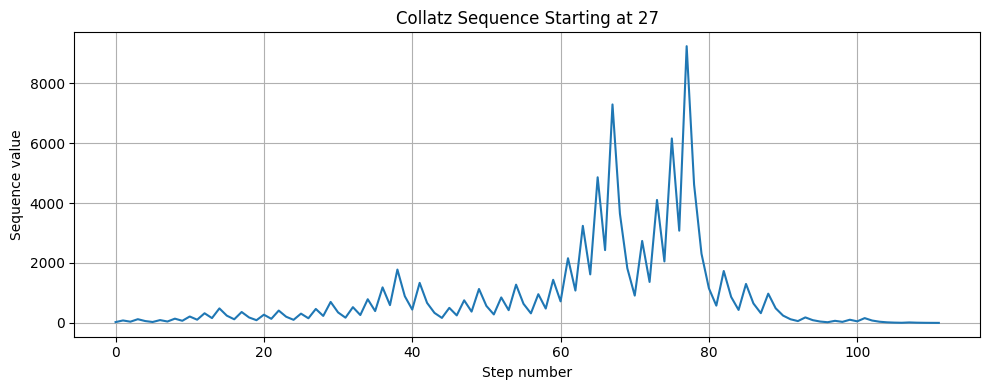

In [ ]:
import matplotlib.pyplot as plt

# A graph helps us see how the Collatz values change.
steps = list(range(len(example_27)))

plt.figure(figsize=(10, 4))
plt.plot(steps, example_27)
plt.title("Collatz Sequence Starting at 27")
plt.xlabel("Step number")
plt.ylabel("Sequence value")
plt.grid(True)
plt.tight_layout()
plt.show()

## 9. Optional: Ask the user for a number

To test interactive input in Google Colab or Jupyter, remove the `#` from the last line of this cell. It is commented out so that **Run All** works without waiting for input.


In [ ]:
def run_collatz_from_input():
    try:
        # Ask for a number and convert it to an integer.
        number = int(input("Enter a positive integer: "))

        # Reuse the sequence function instead of duplicating the logic.
        sequence = collatz_sequence(number)
        print("Sequence:", sequence)
        print("Steps:", len(sequence) - 1)

    except ValueError as error:
        print("Input error:", error)
    except RuntimeError as error:
        print("Stopped:", error)


# run_collatz_from_input()

## 10. Reflection: What did AI improve?

My original Week 3 code calculated and printed the Collatz sequence correctly for normal positive integers. However, it was hard to reuse or test, and it did not handle zero or negative numbers safely.

The AI-assisted version separates the logic into smaller functions, checks inputs, returns a list instead of printing within the calculation, adds a step limit, and includes tests. I also added a graph that makes the behavior of the sequence easier to see.

**What I learned:** Writing reusable functions, validating inputs, and checking code with tests can make even a short Python program more reliable and understandable. I reviewed the improvements and verified that the notebook runs successfully.
